#### Human In The Loop
"""
interrupt()	Pause and wait for human input
Command()	Tell graph where to go / update state
"""

In [1]:
from langchain_tavily import TavilySearch
from typing import TypedDict,Annotated
from langgraph.graph import add_messages
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START,END,StateGraph
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv
load_dotenv()

class state(TypedDict):
    messages : Annotated[list,add_messages]


In [2]:
llm_invoke_bot=init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq"
)
# tool 1
tool_1=TavilySearch(max_result=2)
# tool 2

@tool
def human_intrupt(query:str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]
tools = [tool_1,human_intrupt]
tool_output = llm_invoke_bot.bind_tools(tools)

In [3]:
def chatbot(state:state):
    print("HITTTED")
    response=tool_output.invoke(state["messages"])
    return {"messages":[response]}

In [4]:
builder=StateGraph(state)
builder.add_edge(START,"humaninloop")
builder.add_node("humaninloop",chatbot)
builder.add_node("tools",ToolNode(tools))
builder.add_conditional_edges(      # means: After humaninloop, check a condition and decide where to go.
    "humaninloop",
    tools_condition                 # 👉 This decides whether the AI wants to use a tool. or  SHOULD we go to the tools node?
)
builder.add_edge("tools","humaninloop")

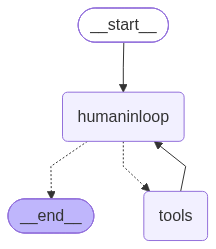

In [5]:
memory = MemorySaver()
graph=builder.compile(checkpointer=memory)
graph

In [6]:
config = {
    "configurable": {
        "thread_id": "user1"
        }
}
response=graph.stream(
    {
        "messages":"I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
    }
,config=config,stream_mode="values")


In [7]:
for i in response:
    print(i)

{'messages': [HumanMessage(content='I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?', additional_kwargs={}, response_metadata={}, id='3f961532-bdeb-460f-8163-e4b062295536')]}
HITTTED
{'messages': [HumanMessage(content='I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?', additional_kwargs={}, response_metadata={}, id='3f961532-bdeb-460f-8163-e4b062295536'), AIMessage(content='', additional_kwargs={'reasoning_content': 'User wants assistant to request assistance from a human. Use human_intrupt.', 'tool_calls': [{'id': 'fc_1ff1c6d7-045c-41b4-a1ab-376d82007a91', 'function': {'arguments': '{"query":"I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"}', 'name': 'human_intrupt'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 355, 'total_tokens': 415, 'completion_time': 0.0

In [8]:
human_reponse={
        "messages":"we the experts are here check langgraph for that"
    }

human_command=Command(resume={"data":human_reponse})
response=graph.stream(human_command,config=config,stream_mode="values")
for i in response:
    print(i["messages"][-1].content)



{"messages": "we the experts are here check langgraph for that"}
HITTTED
Absolutely! Let’s get you set up with a solid foundation for building an AI agent. Below is a step‑by‑step roadmap, key concepts, recommended libraries, and practical code snippets to jump‑start your project. Feel free to ask follow‑up questions on any step or dive deeper into specific parts.

---

## 1. Define the Agent’s Purpose & Scope

| Question | What to Decide |
|----------|----------------|
| **Goal** | What problem is the agent solving? (e.g., personal assistant, data‑analysis bot, customer support) |
| **Interaction** | Text, voice, multimodal? |
| **Domain** | General knowledge, specialized (medicine, law, finance)? |
| **Constraints** | Privacy, latency, cost, deployment (cloud vs edge)? |

**Tip:** Write a short “Mission Statement” for the agent. This keeps design decisions focused.

---

## 2. Choose the Core Components

| Component | Typical Libraries / Models | Why |
|-----------|-----------------

In [9]:
user_answer = input("Do you want expert assistance? (yes/no): ")
human_answer = (
    Command(resume={"data":user_answer}) # Command( update={...},      # update state goto="node_name",  # move to another node resume={...},# resume an interrupt
)

events=graph.stream(
    human_answer,config=config,stream_mode="values"
)
for event in events:
    print(event["messages"][-1].content)



Absolutely! Let’s get you set up with a solid foundation for building an AI agent. Below is a step‑by‑step roadmap, key concepts, recommended libraries, and practical code snippets to jump‑start your project. Feel free to ask follow‑up questions on any step or dive deeper into specific parts.

---

## 1. Define the Agent’s Purpose & Scope

| Question | What to Decide |
|----------|----------------|
| **Goal** | What problem is the agent solving? (e.g., personal assistant, data‑analysis bot, customer support) |
| **Interaction** | Text, voice, multimodal? |
| **Domain** | General knowledge, specialized (medicine, law, finance)? |
| **Constraints** | Privacy, latency, cost, deployment (cloud vs edge)? |

**Tip:** Write a short “Mission Statement” for the agent. This keeps design decisions focused.

---

## 2. Choose the Core Components

| Component | Typical Libraries / Models | Why |
|-----------|---------------------------|-----|
| **LLM** | OpenAI GPT‑4o, Anthropic Claude 3.5 Sonnet, 